# 02 - Volume Visualization

## Objective
Load and visualize 3D brain MRI volumes using NiBabel and Matplotlib.

This notebook explores:
- NIfTI volume loading
- Volume dimensions and intensity distribution
- Anatomical orientations
- Axial, coronal and sagittal visualization

Dataset: BraTS 2024 Adult Glioma

Patient: BraTS-GLI-02547-101

In [1]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
DATASET_ROOT = Path(
    "/kaggle/input/datasets/i212385nomanarif/2024-brats-glioma"
)

PATIENT_ID = "BraTS-GLI-02547-101"

PATIENT_DIR = DATASET_ROOT / PATIENT_ID

MRI_PATH = PATIENT_DIR / f"{PATIENT_ID}-t1n.nii"

print("MRI exists:", MRI_PATH.exists())
print("MRI path:", MRI_PATH)

MRI exists: True
MRI path: /kaggle/input/datasets/i212385nomanarif/2024-brats-glioma/BraTS-GLI-02547-101/BraTS-GLI-02547-101-t1n.nii


In [3]:
nii = nib.load(str(MRI_PATH))

volume = nii.get_fdata()

print("Volume shape:", volume.shape)
print("Data type:", volume.dtype)
print("Minimum intensity:", volume.min())
print("Maximum intensity:", volume.max())
print("Mean intensity:", volume.mean())
print("Standard deviation:", volume.std())

Volume shape: (182, 218, 182)
Data type: float64
Minimum intensity: 0.0
Maximum intensity: 505.9227600097656
Mean intensity: 47.59497981219395
Standard deviation: 104.11911019178928


In [4]:
print("Voxel intensity:", volume[90, 100, 90])

print("Number of zero voxels:", np.sum(volume == 0))

print("Total voxels:", volume.size)

print("Percentage of zero voxels:",
      np.mean(volume == 0) * 100)

Voxel intensity: 304.8159484863281
Number of zero voxels: 5829451
Total voxels: 7221032
Percentage of zero voxels: 80.72877948747492


In [5]:
print("Affine matrix:")
print(nii.affine)

print("\nOriginal orientation:")
print(nib.aff2axcodes(nii.affine))

Affine matrix:
[[  -1.   -0.    0.   90.]
 [  -0.    1.   -0. -126.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]

Original orientation:
('L', 'A', 'S')


In [10]:
nii_ras = nib.as_closest_canonical(nii)

volume_ras = nii_ras.get_fdata()

print("Canonical orientation:",
      nib.aff2axcodes(nii_ras.affine))

print("Affine matrix:")
print(nii_ras.affine)

print("Canonical shape:", volume_ras.shape)

Canonical orientation: ('R', 'A', 'S')
Affine matrix:
[[   1.    0.    0.  -91.]
 [   0.    1.    0. -126.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]
Canonical shape: (182, 218, 182)


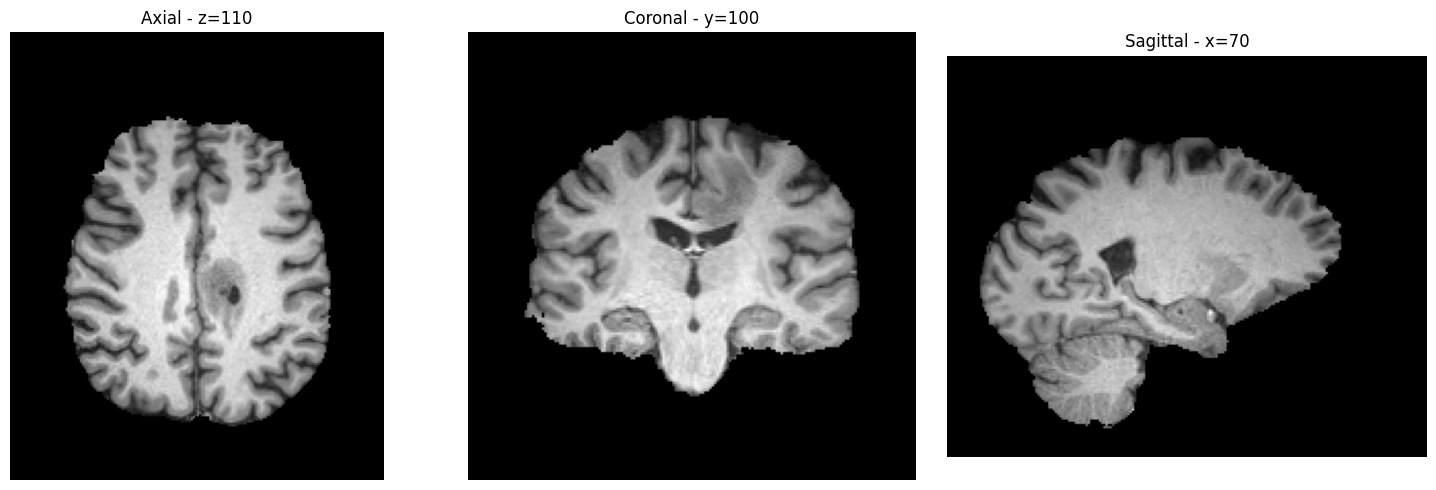

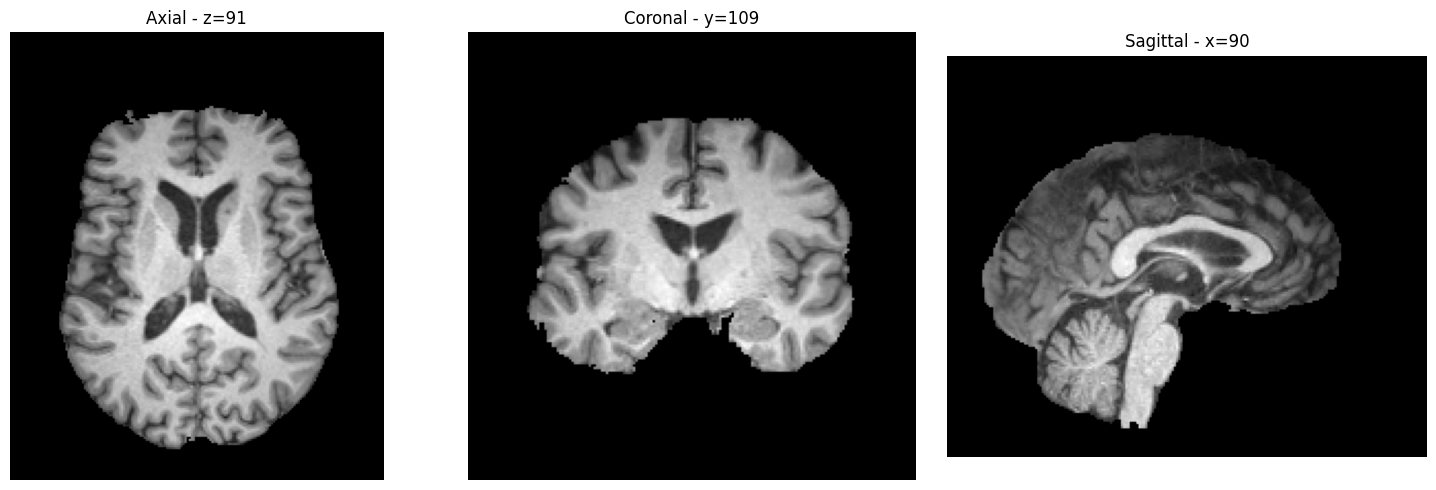

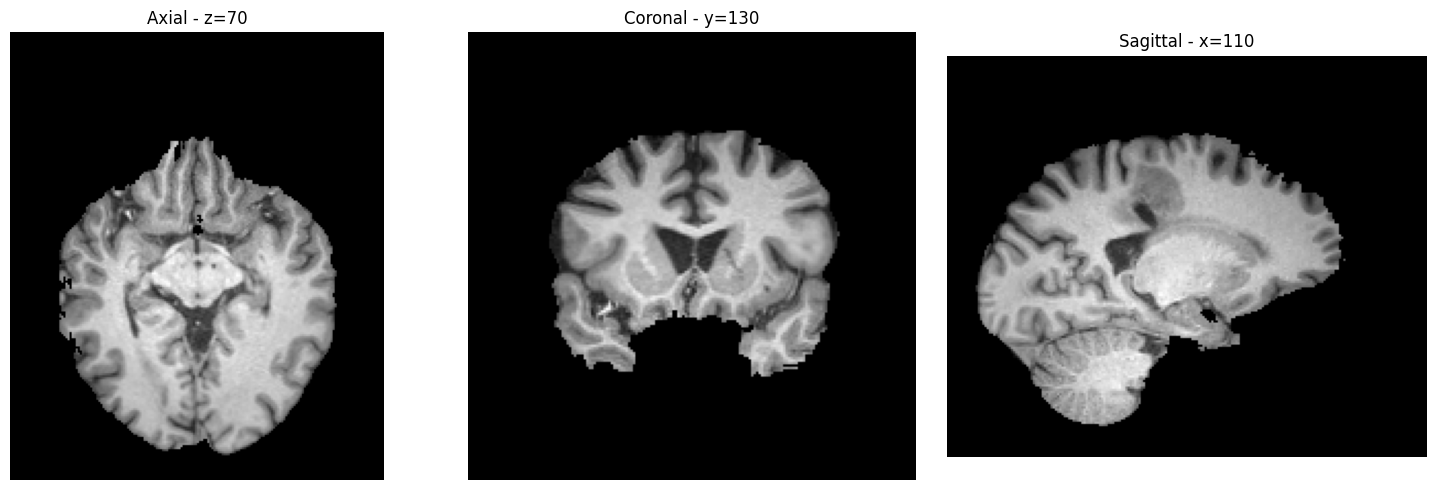

In [11]:
def visualize_slices(volume, x, y, z):

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(np.rot90(volume[:, :, z]), cmap="gray")
    axes[0].set_title(f"Axial - z={z}")

    axes[1].imshow(np.rot90(volume[:, y, :]), cmap="gray")
    axes[1].set_title(f"Coronal - y={y}")

    axes[2].imshow(np.rot90(volume[x, :, :]), cmap="gray")
    axes[2].set_title(f"Sagittal - x={x}")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_slices(volume_ras, 70, 100, 110)
visualize_slices(volume_ras, 90, 109, 91)
visualize_slices(volume_ras, 110, 130, 70)

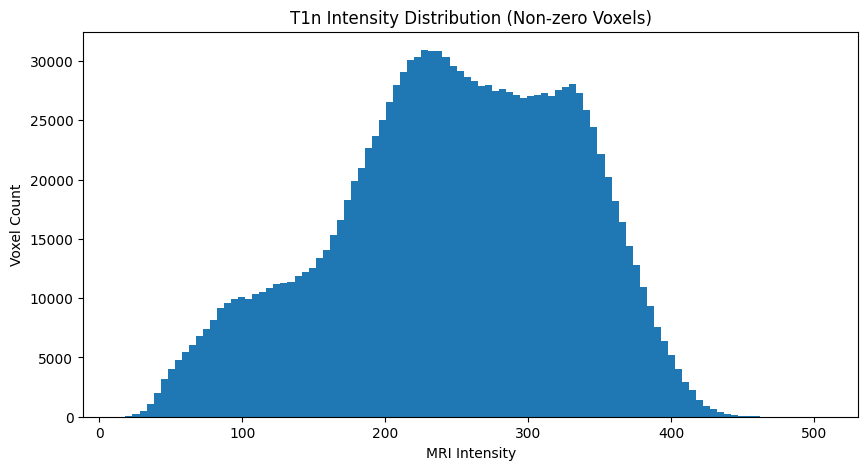

In [13]:
nonzero_voxels = volume_ras[volume_ras > 0]

plt.figure(figsize=(10, 5))

plt.hist(nonzero_voxels, bins=100)

plt.xlabel("MRI Intensity")
plt.ylabel("Voxel Count")
plt.title("T1n Intensity Distribution (Non-zero Voxels)")

plt.show()